---
downloads:
  - file: tp02_trajectoire_equations_horaires_teacher.ipynb
    title: Notebook enseignant
    filename: tp02_trajectoire_equations_horaires_enseignant.ipynb
  - file: ../notebooks_student/tp02_trajectoire_equations_horaires_student.ipynb
    title: Notebook étudiant
    filename: tp02_trajectoire_equations_horaires_etudiant.ipynb
---


# TP 02 — Trajectoire et équations horaires

Dans ce TP, nous étudions le lien entre les équations horaires et la
trajectoire d'un point matériel. À partir de plusieurs exemples, nous
observerons comment l'évolution temporelle de ses coordonnées détermine la
forme de sa trajectoire.


:::{important} Versions enseignant
Cette page présente la version **corrigée**, destinée aux enseignants.

Pour télécharger la version à distribuer aux étudiants et à déposer sur
Boostcamp, utilisez le bouton **Notebook étudiant** dans le menu de
téléchargement situé en haut de la page.

Les liens suivants ouvrent les notebooks dans Google Colab :

- [Notebook enseignant](https://colab.research.google.com/github/ECE-Ecole-Ingenieurs/cours-physique/blob/main/notebooks/tp02_trajectoire_equations_horaires_teacher.ipynb) ;
- [Notebook étudiant](https://colab.research.google.com/github/ECE-Ecole-Ingenieurs/cours-physique/blob/main/notebooks_student/tp02_trajectoire_equations_horaires_student.ipynb).
:::


**Importation bibliothèques**

In [1]:
import numpy as np  # Manipulation des vecteurs et opérations matricielles
import matplotlib.pyplot as plt  # Tracé des figures 2D et 3D
from ipywidgets import interact, Checkbox, FloatSlider  # Widgets interactifs (curseurs et cases à cocher)

## 1. Rappel de cours

Pour décrire le mouvement d'un point matériel $M$, on repère sa position à
chaque instant. Ses coordonnées sont alors des fonctions du temps :

$$
x = x(t), \qquad y = y(t), \qquad z = z(t)
$$

Ces fonctions sont appelées les **équations horaires** du mouvement.

À partir d'elles, on peut :

- connaître la position du point à tout instant ;
- tracer sa trajectoire ;
- étudier la vitesse et l'accélération plus tard.

Dans ce TP, nous allons d'abord visualiser le lien entre :

- le temps $t$ ;
- les composantes $x(t)$, $y(t)$, $z(t)$ ;
- la trajectoire dans l'espace.


## 2. Équations horaires cartésiennes

Considérons un point matériel $M$ dont la position est décrite dans le repère
cartésien $(O,\vec e_x,\vec e_y,\vec e_z)$.

À $t=0$, le point se trouve à l'origine du repère :

$$
x(0)=y(0)=z(0)=0.
$$

Ses coordonnées évoluent ensuite selon les équations horaires suivantes :

$$
x(t)=At,\qquad y(t)=Bt,\qquad z(t)=C\sin(\omega t),
$$

où $A$, $B$, $C$ et $\omega$ sont des constantes.

### 2.1 Théorie

:::{admonition} ✍️ Questions
:class: tip

1. Déterminez les dimensions des coefficients $A$, $B$ et $C$.
2. Quelle interprétation physique peut-on donner à $A$, $B$, $C$ et
   $\omega$ ?
3. Pourquoi l'argument $\omega t$ de la fonction sinus doit-il être sans
   dimension ?
:::

:::{admonition} Réponses
:class: note

1. Puisque $x$, $y$ et $z$ sont des longueurs et que $t$ est un temps,
   $[A]=[B]=L\,T^{-1}$ et $[C]=L$.
2. Les coefficients $A$ et $B$ sont les composantes constantes de la vitesse
   linéaire suivant $Ox$ et $Oy$. Le coefficient $C$ est l'amplitude de
   l'oscillation suivant $Oz$, tandis que $\omega$ est sa pulsation, ou
   vitesse angulaire dans ce modèle.
3. L'argument d'une fonction trigonométrique doit être sans dimension. Ainsi,
   $[\omega t]=1$, donc $[\omega]=T^{-1}$ ; dans le SI, $\omega$ s'exprime
   en $\mathrm{rad\,s^{-1}}$.
:::

### 2.2 Implémentation numérique

:::{admonition} 💻 Code
:class: tip

Codez la fonction `equations_horaires_cartesiennes` qui renvoie $x(t)$, $y(t)$
et $z(t)$ à partir des paramètres du mouvement.
:::

In [2]:
def equations_horaires_cartesiennes(t, A=0.5, B=0.2, C=1.5, omega=1.2):
    """
    Calcule les coordonnées cartésiennes en fonction du temps.

    Paramètres
    ----------
    t : float ou np.ndarray
        Instant(s) considéré(s) [s].
    A, B : float
        Composantes de la vitesse linéaire selon x et y [m/s].
    C : float
        Amplitude de l'oscillation selon z [m].
    omega : float
        Pulsation de l'oscillation [rad/s].

    Renvoie
    -------
    x, y, z : float ou np.ndarray
        Coordonnées cartésiennes [m].
    """
    x = A * t
    y = B * t
    z = C * np.sin(omega * t)
    return x, y, z


### 2.3 Analyse

Le code suivant permet de tracer la trajectoire spatiale en 3D du point $M$
à partir des équations horaires obtenues précédemment. Exécutez-le, puis
faites varier les paramètres et l'instant considéré afin d'observer leur
influence sur le mouvement et sur le vecteur position $\overrightarrow{OM}$.

Examinez également les projections de la trajectoire sur les plans $xy$, $xz$
et $yz$, puis reliez chacune d'elles aux deux coordonnées cartésiennes du plan
correspondant. Dans la version interactive, les cases à cocher permettent
d'afficher ou de masquer chaque projection indépendamment.

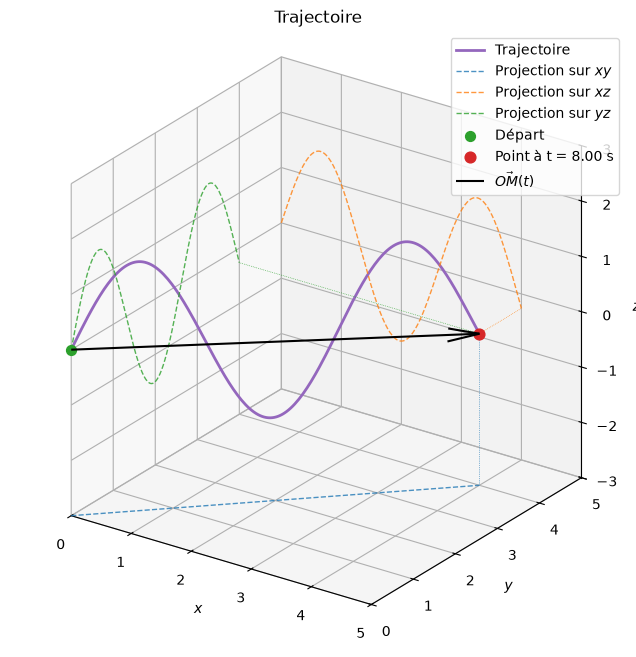

In [3]:
def tracer_mouvement_cartesien(A=0.5, B=0.5, C=1.5, omega=1.2, t_max=10.0, t_current=10.0, afficher_xy=True, afficher_xz=True, afficher_yz=True):
    """Trace la trajectoire cartésienne et ses projections jusqu'à l'instant courant."""

    # Vecteur temps
    n_points = 200
    t = np.linspace(0.0, t_current, n_points)

    # Évolution des coordonnées en fonction du temps
    x, y, z = equations_horaires_cartesiennes(t, A=A, B=B, C=C, omega=omega)

    # Dernier point
    x_c, y_c, z_c = x[-1], y[-1], z[-1]

    fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={"projection": "3d"})
    ax.set_proj_type("ortho")
    ax.view_init(elev=25,azim=-55)
    ax.set_box_aspect((1,1,1))

    # Trajectoire
    ax.plot(x, y, z, color='tab:purple', linewidth=2, label='Trajectoire')

    # Projections et segments orthogonaux depuis M
    if afficher_xy:
        ax.plot(x, y, -3*np.ones_like(z), linestyle='--', color='tab:blue', linewidth=1, alpha=0.8, label=r'Projection sur $xy$')
        ax.plot([x_c, x_c], [y_c, y_c], [z_c, -3], linestyle=':', color='tab:blue', linewidth=0.5)

    if afficher_xz:
        ax.plot(x, 5*np.ones_like(y), z, linestyle='--', color='tab:orange', linewidth=1, alpha=0.8, label=r'Projection sur $xz$')
        ax.plot([x_c, x_c], [y_c, 5], [z_c, z_c], linestyle=':', color='tab:orange', linewidth=0.5)

    if afficher_yz:
        ax.plot(np.zeros_like(x), y, z, linestyle='--', color='tab:green', linewidth=1, alpha=0.8, label=r'Projection sur $yz$')
        ax.plot([x_c, 0], [y_c, y_c], [z_c, z_c], linestyle=':', color='tab:green', linewidth=0.5)

    ax.scatter(x[0], y[0], z[0], color='tab:green', s=50, label='Départ')
    ax.scatter(x_c, y_c, z_c, color='tab:red', s=60, label=rf'Point à t = {t_current:.2f} s')
    ax.quiver(0, 0, 0, x_c, y_c, z_c, color='black', arrow_length_ratio=0.08, label=r'$\vec{OM}(t)$')

    # Étiquettes
    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$y$")
    ax.set_zlabel(r"$z$")
    ax.set_xlim([0, 5])
    ax.set_ylim([0, 5])
    ax.set_zlim([-3, 3])

    ax.set_title('Trajectoire')
    ax.legend(loc='upper right')

    plt.show()
    plt.close(fig)

tracer_mouvement_cartesien(t_current=8.0)


In [4]:
def update_figure_cartesienne(A, B, C, omega, t_current, afficher_xy, afficher_xz, afficher_yz):
    tracer_mouvement_cartesien(
        A=A,
        B=B,
        C=C,
        omega=omega,
        t_current=t_current,
        afficher_xy=afficher_xy,
        afficher_xz=afficher_xz,
        afficher_yz=afficher_yz,
    )


interact(
    update_figure_cartesienne,
    A=FloatSlider(value=0.5, min=0.0, max=0.5, step=0.05),
    B=FloatSlider(value=0.5, min=0.0, max=0.5, step=0.05),
    C=FloatSlider(value=1.5, min=0.0, max=3.0, step=0.1),
    omega=FloatSlider(value=1.2, min=0.2, max=3.0, step=0.1),
    t_current=FloatSlider(value=8.0, min=0.0, max=10.0, step=0.2, description='Temps (s)'),
    afficher_xy=Checkbox(value=True, description='Projection xy'),
    afficher_xz=Checkbox(value=True, description='Projection xz'),
    afficher_yz=Checkbox(value=True, description='Projection yz'),
);


interactive(children=(FloatSlider(value=0.5, description='A', max=0.5, step=0.05), FloatSlider(value=0.5, desc…

:::{admonition} 🔍 Exploration
:class: tip

1. Affichez uniquement la projection sur le plan $xy$. Quelle forme prend-elle ?
   Justifiez votre réponse à partir de $x(t)$ et $y(t)$.
2. Comparez les projections sur les plans $xz$ et $yz$. Pourquoi présentent-elles
   toutes les deux une oscillation ?
3. Que devient la trajectoire lorsque $C=0$ ?
4. Faites varier $C$, puis $\omega$. Comment chacun de ces paramètres
   modifie-t-il la trajectoire ?
:::

:::{admonition} Réponses
:class: note

1. La projection sur $xy$ est une droite. En éliminant le temps entre
   $x(t)=At$ et $y(t)=Bt$, on obtient $y=(B/A)x$ lorsque $A\neq 0$ ; si
   $A=0$, la projection est la droite $x=0$.
2. Les deux projections contiennent la coordonnée
   $z(t)=C\sin(\omega t)$ : elles reproduisent donc son oscillation.
3. Si $C=0$, alors $z(t)=0$ et le point suit une droite dans le plan $xy$.
4. Augmenter $C$ augmente l'amplitude des oscillations verticales. Augmenter
   $\omega$ augmente le nombre d'oscillations effectuées pendant une même
   durée.
:::

:::{important}
Pour afficher la version interactive, ouvrez le **Notebook enseignant** en
local ou ouvrez ce notebook dans Google Colab.
:::

## 3. Équations horaires cylindriques

Dans un repère cylindrique, la position d'un point matériel $M$ est décrite
par sa distance $r(t)$ à l'axe $Oz$, son angle $\theta(t)$ autour de cet axe
et sa hauteur $h(t)$. Son vecteur position s'écrit :

$$
\overrightarrow{OM}(t) = r(t)\,\overrightarrow{u_r} + h(t)\,\overrightarrow{u_z}
$$

En projetant ce vecteur sur la base cartésienne, on obtient les équations
horaires du point $M$ :

$$
\begin{cases}
x(t) = r(t)\cos\theta(t) \\
y(t) = r(t)\sin\theta(t) \\
z(t) = h(t)
\end{cases}
$$

Nous commençons par le cas le plus simple, où le rayon reste constant et où le
point part du plan $z=0$ :

$$
\begin{cases}
r(t) = r_0 \\
\theta(t) = A t \\
h(t) = B t
\end{cases}
$$



### 3.1 Théorie

:::{admonition} ✍️ Questions
:class: tip

1. Déterminez les dimensions et les unités SI de $r_0$, $A$ et $B$. Quelle
   interprétation physique peut-on donner à ces trois coefficients ?
2. Quelle forme prend la trajectoire du point $M$ ?
:::

:::{admonition} Réponses
:class: note

1. Le rayon $r_0$ est une longueur : $[r_0]=L$ et il s'exprime en mètres.
   Le coefficient $A$ est une vitesse angulaire : $[A]=T^{-1}$ et il
   s'exprime en $\mathrm{rad\,s^{-1}}$. Le coefficient $B$ est une vitesse
   linéaire suivant $Oz$ : $[B]=L\,T^{-1}$ et il s'exprime en
   $\mathrm{m\,s^{-1}}$.
2. Le point décrit une hélice circulaire autour de l'axe $Oz$.
:::

### 3.2 Implémentation numérique

:::{admonition} 💻 Code
:class: tip

Codez la fonction `equations_horaires_cylindriques` qui renvoie les
coordonnées cartésiennes $x(t)$, $y(t)$ et $z(t)$ à partir de $t$, $r_0$,
$A$ et $B$.
:::

In [5]:
def equations_horaires_cylindriques(t, r0=2.5, A=1.0, B=0.5):
    """
    Calcule les coordonnées cartésiennes du mouvement cylindrique simple.

    Paramètres
    ----------
    t : float ou np.ndarray
        Instant(s) considéré(s) [s].
    r0 : float
        Rayon constant [m].
    A : float
        Vitesse angulaire [rad/s].
    B : float
        Vitesse verticale [m/s].

    Renvoie
    -------
    x, y, z : float ou np.ndarray
        Coordonnées cartésiennes [m].
    """
    x = r0 * np.cos(A * t)
    y = r0 * np.sin(A * t)
    z = B * t

    return x, y, z


### 3.3 Analyse

Le code suivant permet de tracer la trajectoire spatiale en 3D du point $M$
à partir des équations horaires obtenues précédemment. Exécutez-le, puis
faites varier les paramètres afin d'observer leur influence sur le mouvement.

Examinez également les projections de la trajectoire sur les plans $xy$, $xz$
et $yz$, puis reliez chacune d'elles aux deux coordonnées cartésiennes du plan
correspondant. Dans la version interactive, les cases à cocher permettent
d'afficher ou de masquer chaque projection indépendamment.


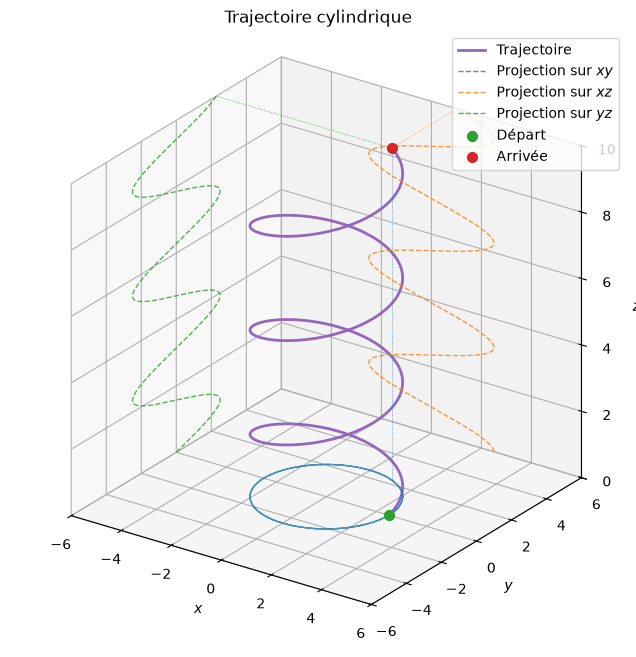

In [6]:
def tracer_mouvement_cylindrique(r0=2.5, A=1.0, B=0.5, t_max=20.0,
                                  afficher_xy=True, afficher_xz=True,
                                  afficher_yz=True):
    """Trace la trajectoire cylindrique simple et ses projections."""
    t = np.linspace(0.0, t_max, 400)
    x, y, z = equations_horaires_cylindriques(t, r0=r0, A=A, B=B)

    x_lim = 6.0
    y_lim = 6.0
    z_min = 0.0
    z_max = 10.0

    x_c, y_c, z_c = x[-1], y[-1], z[-1]

    fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={"projection": "3d"})
    ax.set_proj_type("ortho")
    ax.view_init(elev=25, azim=-55)
    ax.set_box_aspect((1, 1, 1))

    ax.plot(x, y, z, color='tab:purple', linewidth=2, label='Trajectoire')

    if afficher_xy:
        ax.plot(x, y, z_min*np.ones_like(z), linestyle='--', color='tab:blue', linewidth=1, alpha=0.8, label=r'Projection sur $xy$')
        ax.plot([x_c, x_c], [y_c, y_c], [z_c, z_min], linestyle=':', color='tab:blue', linewidth=0.5)

    if afficher_xz:
        ax.plot(x, y_lim*np.ones_like(y), z, linestyle='--', color='tab:orange', linewidth=1, alpha=0.8, label=r'Projection sur $xz$')
        ax.plot([x_c, x_c], [y_c, y_lim], [z_c, z_c], linestyle=':', color='tab:orange', linewidth=0.5)

    if afficher_yz:
        ax.plot(-x_lim*np.ones_like(x), y, z, linestyle='--', color='tab:green', linewidth=1, alpha=0.8, label=r'Projection sur $yz$')
        ax.plot([x_c, -x_lim], [y_c, y_c], [z_c, z_c], linestyle=':', color='tab:green', linewidth=0.5)

    ax.scatter(x[0], y[0], z[0], color='tab:green', s=50, label='Départ')
    ax.scatter(x_c, y_c, z_c, color='tab:red', s=50, label='Arrivée')
    ax.set_xlim(-x_lim, x_lim)
    ax.set_ylim(-y_lim, y_lim)
    ax.set_zlim(z_min, z_max)
    ax.set_xlabel(r'$x$')
    ax.set_ylabel(r'$y$')
    ax.set_zlabel(r'$z$')
    ax.set_title('Trajectoire cylindrique')
    ax.legend(loc='upper right')

    plt.show()
    plt.close(fig)

tracer_mouvement_cylindrique()


In [7]:
interact(
    tracer_mouvement_cylindrique,
    r0=FloatSlider(value=2.5, min=0.5, max=5.0, step=0.5),
    A=FloatSlider(value=1.0, min=0.0, max=3.0, step=0.2),
    B=FloatSlider(value=0.5, min=0.0, max=0.5, step=0.1),
    t_max=FloatSlider(value=20.0, min=4.0, max=20.0, step=0.25),
    afficher_xy=Checkbox(value=True, description='Projection xy'),
    afficher_xz=Checkbox(value=True, description='Projection xz'),
    afficher_yz=Checkbox(value=True, description='Projection yz'),
);


interactive(children=(FloatSlider(value=2.5, description='r0', max=5.0, min=0.5, step=0.5), FloatSlider(value=…

:::{admonition} 🔍 Exploration
:class: tip

1. Faites varier les paramètres $r_0$, $A$ et $B$. Quelle est l'influence de
   chacun d'eux sur la trajectoire ?
2. Que pouvez-vous en déduire sur les composantes et la norme de la vitesse du
   point $M$ ?
3. Décrivez la trajectoire obtenue lorsque $A=0$, puis lorsque $B=0$.
:::

:::{admonition} Réponses
:class: note

1. Le paramètre $r_0$ fixe la distance à l'axe $Oz$, $A$ contrôle la rapidité
   de rotation et $B$ contrôle le déplacement vertical. Leur combinaison
   détermine le rayon et l'espacement vertical des tours de l'hélice.
2. La composante radiale de la vitesse est nulle, sa composante tangentielle
   vaut $r_0A$ et sa composante verticale vaut $B$. Sa norme
   $\sqrt{(r_0A)^2+B^2}$ est constante, même si la direction du vecteur
   vitesse change au cours du mouvement.
3. Si $A=0$, le point suit une droite verticale à distance constante $r_0$ de
   l'axe $Oz$. Si $B=0$, il décrit un cercle de rayon $r_0$ dans le plan
   $z=0$.
:::

:::{important}
Pour afficher la version interactive, ouvrez le **Notebook enseignant** en
local ou ouvrez ce notebook dans Google Colab.
:::


## 4. Généralisation : rayon variable

Passons maintenant à un cas plus général, dans lequel le rayon varie au cours
du temps :

$$
\begin{cases}
r(t) = r_0 + a_r t \\
\theta(t) = A t \\
h(t) = B t
\end{cases}
$$


### 4.1 Théorie

:::{admonition} ✍️ Questions
:class: tip

1. Déterminez les dimensions et les unités SI de $r_0$, $a_r$, $A$ et $B$.
   Quelle interprétation physique peut-on donner à ces quatre coefficients ?
2. Quelle condition le rayon $r(t)$ doit-il respecter pour conserver un sens
   physique ?
:::

:::{admonition} Réponses
:class: note

1. $r_0$ est le rayon initial : $[r_0]=L$ et il s'exprime en mètres.
   Le coefficient $a_r$ est une vitesse radiale : $[a_r]=L\,T^{-1}$ et il
   s'exprime en $\mathrm{m\,s^{-1}}$. Les coefficients $A$ et $B$ conservent
   l'interprétation établie à la section précédente : $A$ est une vitesse
   angulaire en $\mathrm{rad\,s^{-1}}$ et $B$ une vitesse verticale en
   $\mathrm{m\,s^{-1}}$.
2. Le rayon doit rester positif ou nul : $r(t)=r_0+a_r t\geq 0$ pendant tout
   l'intervalle étudié.
:::

### 4.2 Implémentation numérique

:::{admonition} 💻 Code
:class: tip

Codez la fonction `equations_horaires_cylindriques_generales` qui renvoie les
coordonnées cartésiennes $x(t)$, $y(t)$ et $z(t)$ à partir de $t$, $r_0$,
$a_r$, $A$ et $B$.
:::

In [8]:
def equations_horaires_cylindriques_generales(t, r0=2.0, a_r=0.08, A=1.5, B=0.3):
    """
    Calcule les coordonnées cartésiennes du mouvement cylindrique à rayon
    variable.

    Paramètres
    ----------
    t : float ou np.ndarray
        Instant(s) considéré(s) [s].
    r0 : float
        Rayon initial [m].
    a_r : float
        Vitesse radiale [m/s].
    A : float
        Vitesse angulaire [rad/s].
    B : float
        Vitesse verticale [m/s].

    Renvoie
    -------
    x, y, z : float ou np.ndarray
        Coordonnées cartésiennes [m].
    """
    x = (r0 + a_r * t) * np.cos(A * t)
    y = (r0 + a_r * t) * np.sin(A * t)
    z = B * t

    return x, y, z


### 4.3 Analyse

Le code suivant permet de tracer la trajectoire spatiale en 3D du point $M$
à partir des équations horaires obtenues précédemment. Exécutez-le, puis
faites varier les paramètres afin d'observer leur influence sur le mouvement.

Examinez également les projections de la trajectoire sur les plans $xy$, $xz$
et $yz$, puis reliez chacune d'elles aux deux coordonnées cartésiennes du plan
correspondant. Dans la version interactive, les cases à cocher permettent
d'afficher ou de masquer chaque projection indépendamment.

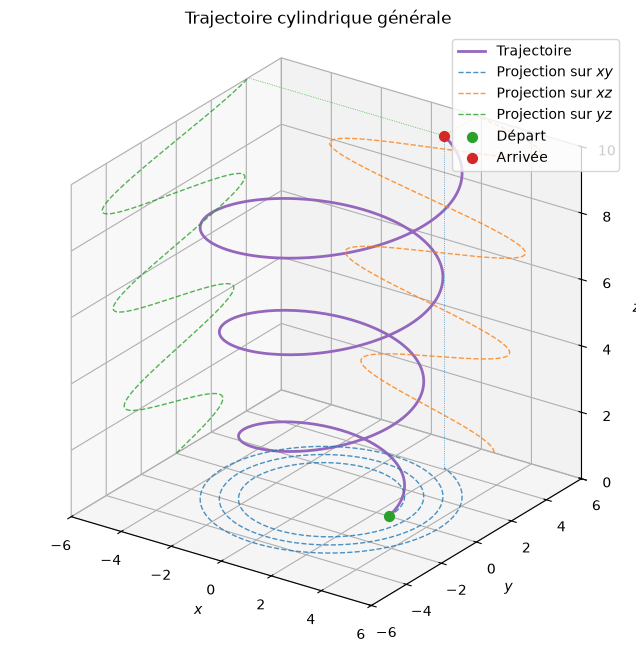

In [9]:
def tracer_mouvement_cylindrique_general(r0=2.5, a_r=0.1, A=1.0, B=0.5,
                                          t_max=20.0, afficher_xy=True,
                                          afficher_xz=True, afficher_yz=True):
    """Trace la trajectoire cylindrique à rayon variable et ses projections."""
    # Vecteur temps
    t = np.linspace(0.0, t_max, 400)

    # Évolution des coordonnées en fonction du temps
    x, y, z = equations_horaires_cylindriques_generales(t, r0=r0, a_r=a_r, A=A, B=B)

    x_lim = 6.0
    y_lim = 6.0
    z_min = 0.0
    z_max = 10.0

    # Dernier point
    x_c, y_c, z_c = x[-1], y[-1], z[-1]

    fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={"projection": "3d"})
    ax.set_proj_type("ortho")
    ax.view_init(elev=25, azim=-55)
    ax.set_box_aspect((1, 1, 1))

    # Trajectoire
    ax.plot(x, y, z, color='tab:purple', linewidth=2, label='Trajectoire')

    # Projections et segments orthogonaux depuis M
    if afficher_xy:
        ax.plot(x, y, z_min*np.ones_like(z), linestyle='--', color='tab:blue', linewidth=1, alpha=0.8, label=r'Projection sur $xy$')
        ax.plot([x_c, x_c], [y_c, y_c], [z_c, z_min], linestyle=':', color='tab:blue', linewidth=0.5)

    if afficher_xz:
        ax.plot(x, y_lim*np.ones_like(y), z, linestyle='--', color='tab:orange', linewidth=1, alpha=0.8, label=r'Projection sur $xz$')
        ax.plot([x_c, x_c], [y_c, y_lim], [z_c, z_c], linestyle=':', color='tab:orange', linewidth=0.5)

    if afficher_yz:
        ax.plot(-x_lim*np.ones_like(x), y, z, linestyle='--', color='tab:green', linewidth=1, alpha=0.8, label=r'Projection sur $yz$')
        ax.plot([x_c, -x_lim], [y_c, y_c], [z_c, z_c], linestyle=':', color='tab:green', linewidth=0.5)

    ax.scatter(x[0], y[0], z[0], color='tab:green', s=50, label='Départ')
    ax.scatter(x_c, y_c, z_c, color='tab:red', s=50, label='Arrivée')

    # Étiquettes
    ax.set_xlim(-x_lim, x_lim)
    ax.set_ylim(-y_lim, y_lim)
    ax.set_zlim(z_min, z_max)
    ax.set_xlabel(r'$x$')
    ax.set_ylabel(r'$y$')
    ax.set_zlabel(r'$z$')
    ax.set_title('Trajectoire cylindrique générale')
    ax.legend(loc='upper right')

    plt.show()
    plt.close(fig)

tracer_mouvement_cylindrique_general()


In [10]:
interact(
    tracer_mouvement_cylindrique_general,
    r0=FloatSlider(value=2.5, min=0.5, max=3.0, step=0.1),
    a_r=FloatSlider(value=0.1, min=-0.025, max=0.15, step=0.005),
    A=FloatSlider(value=1.0, min=0.0, max=3.0, step=0.1),
    B=FloatSlider(value=0.5, min=0.0, max=0.5, step=0.1),
    t_max=FloatSlider(value=20.0, min=4.0, max=20.0, step=0.25, description='Temps (s)'),
    afficher_xy=Checkbox(value=True, description='Projection xy'),
    afficher_xz=Checkbox(value=True, description='Projection xz'),
    afficher_yz=Checkbox(value=True, description='Projection yz'),
);


interactive(children=(FloatSlider(value=2.5, description='r0', max=3.0, min=0.5), FloatSlider(value=0.1, descr…

:::{admonition} 🔍 Exploration
:class: tip

1. Réglez $a_r=0$. Quelle forme prend la trajectoire ? Comparez-la avec celle
   de la section 3.
2. Pour $a_r\neq 0$, quelle forme prend la projection de la trajectoire sur le
   plan $xy$ ? Ce résultat vous paraît-il cohérent ? Justifiez votre réponse à
   partir des équations horaires.
:::

:::{admonition} Réponses
:class: note

1. Lorsque $a_r=0$, le rayon reste constant : on retrouve l'hélice circulaire
   étudiée à la section 3.
2. Pour $A\neq 0$ et $a_r\neq 0$, la projection sur le plan $xy$ est une
   spirale. En éliminant le temps entre $r(t)=r_0+a_rt$ et $\theta(t)=At$, on
   obtient $r(\theta)=r_0+(a_r/A)\theta$. Le rayon varie donc linéairement avec
   l'angle : la spirale s'ouvre si $a_r>0$ et se resserre si $a_r<0$.
:::

:::{important}
Pour afficher la version interactive, ouvrez le **Notebook enseignant** en
local ou ouvrez ce notebook dans Google Colab.
:::

## 5. Application : la cycloïde

Pour terminer, étudions une trajectoire classique de la cinématique : la
**cycloïde**. Cette courbe est décrite par un point matériel $M$ fixé sur la
circonférence d'une roue de rayon $R$ roulant sans glissement sur un plan
horizontal.

Le mouvement est entièrement décrit par les équations horaires suivantes :

$$
\begin{cases}
x(t)=R\left(\omega t-\sin(\omega t)\right),\\[0.3em]
y(t)=R\left(1-\cos(\omega t)\right).
\end{cases}
$$

où :

- $R$ est le rayon de la roue ;
- $\omega$ est la vitesse angulaire constante de la roue.

Le vecteur position du point $M$ s'écrit alors :

$$
\overrightarrow{OM}(t)
=x(t)\,\overrightarrow{e_x}
+y(t)\,\overrightarrow{e_y}.
$$

### 5.1 Théorie

:::{admonition} ✍️ Questions
:class: tip

1. Déterminez les dimensions et les unités SI de $R$ et $\omega$.
2. La coordonnée $y(t)$ est-elle périodique ? Qu'en est-il de la coordonnée
   $x(t)$ ? Justifiez vos réponses.
3. À quoi correspond physiquement le terme $R\,\omega\,t$ dans l'expression
   de $x(t)$ ?
:::

:::{admonition} Réponses
:class: note

1. Le rayon est une longueur : $[R]=L$ et il s'exprime en mètres. La vitesse
   angulaire vérifie $[\omega]=T^{-1}$ et s'exprime en
   $\mathrm{rad\,s^{-1}}$.
2. La coordonnée $y(t)$ est périodique, de période
   $T=2\pi/\omega$, car le cosinus reprend la même valeur lorsque son argument
   augmente de $2\pi$. En revanche, $x(t)$ n'est pas périodique à cause du
   terme linéaire $R\omega t$ : $x(t+T)=x(t)+2\pi R$.
3. Le terme $R\omega t$ représente le déplacement horizontal du centre de la
   roue depuis l'instant initial. En effet, le roulement sans glissement
   impose une vitesse de translation constante $v=R\omega$.
:::

### 5.2 Implémentation numérique

:::{admonition} 💻 Code
:class: tip

Codez la fonction `equations_horaires_cycloide` qui renvoie les coordonnées
cartésiennes $x(t)$ et $y(t)$ à partir de $t$, $R$ et $\omega$.
:::

In [11]:
def equations_horaires_cycloide(t, R=1.0, omega=1.0):
    """
    Calcule les coordonnées cartésiennes d'un point de la cycloïde.

    Paramètres
    ----------
    t : float ou np.ndarray
        Instant(s) considéré(s) [s].
    R : float
        Rayon de la roue [m].
    omega : float
        Vitesse angulaire de la roue [rad/s].

    Renvoie
    -------
    x, y : float ou np.ndarray
        Coordonnées cartésiennes [m].
    """
    x = R * (omega * t - np.sin(omega * t))
    y = R * (1.0 - np.cos(omega * t))

    return x, y

### 5.3 Analyse

Le code suivant représente la trajectoire parcourue par le point $M$ jusqu'à
l'instant considéré. La roue, son centre et le rayon reliant son centre à
$M$ sont également affichés pour faciliter l'interprétation géométrique.

Exécutez le code, puis faites varier les paramètres afin d'analyser leur
influence sur le mouvement. Les limites des axes restent fixes pendant
l'exploration.

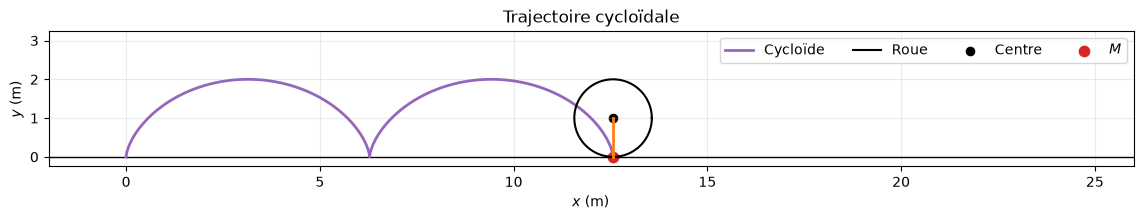

In [12]:
def tracer_cycloide(R=1.0, omega=1.0, t_current=4.0 * np.pi):
    """Trace la cycloïde parcourue par le point M jusqu'à l'instant courant."""
    # Trajectoire jusqu'à l'instant courant
    t = np.linspace(0.0, t_current, 500)
    x, y = equations_horaires_cycloide(t, R=R, omega=omega)

    # Position actuelle de la roue et du point M
    angle = omega * t_current
    x_centre, y_centre = R * angle, R
    x_m, y_m = equations_horaires_cycloide(t_current, R=R, omega=omega)

    alpha = np.linspace(0.0, 2.0 * np.pi, 200)
    x_roue = x_centre + R * np.cos(alpha)
    y_roue = y_centre + R * np.sin(alpha)

    # Tracés
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.axhline(0.0, color='black', linewidth=1)
    ax.plot(x, y, color='tab:purple', linewidth=2, label='Cycloïde')
    ax.plot(x_roue, y_roue, color='black', linewidth=1.5, label='Roue')
    ax.plot([x_centre, x_m], [y_centre, y_m], color='tab:orange', linewidth=2)
    ax.scatter(x_centre, y_centre, color='black', s=35, label='Centre')
    ax.scatter(x_m, y_m, color='tab:red', s=55, label='$M$')

    ax.set_xlim(-2.0, 26.0)
    ax.set_ylim(-0.25, 3.25)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel(r'$x$ (m)')
    ax.set_ylabel(r'$y$ (m)')
    ax.set_title('Trajectoire cycloïdale')
    ax.grid(alpha=0.25)
    ax.legend(loc='upper right', ncol=4)
    plt.show()
    plt.close(fig)

tracer_cycloide()

In [13]:
interact(
    tracer_cycloide,
    R=FloatSlider(value=1.0, min=0.0, max=1.5, step=0.1, description='R (m)'),
    omega=FloatSlider(value=1.0, min=0.5, max=1.25, step=0.05, description='ω (rad/s)'),
    t_current=FloatSlider(value=4.0*np.pi, min=0.0, max=4.0*np.pi, step=0.1, description='Temps (s)'),
);

interactive(children=(FloatSlider(value=1.0, description='R (m)', max=1.5), FloatSlider(value=1.0, description…

:::{admonition} 🔍 Exploration
:class: tip

1. Quelle est l'influence du rayon $R$ sur la trajectoire ?
2. Quelle est l'influence de la vitesse angulaire $\omega$ sur le mouvement ?
3. À quels instants le point $M$ touche-t-il le sol ?
4. Quelle est la trajectoire du centre de la roue ?
5. Pour une durée donnée, quel jeu de paramètres permet de maximiser la
   distance parcourue par le centre de la roue ?
:::

:::{admonition} Réponses
:class: note

1. Le rayon $R$ fixe l'échelle géométrique de la cycloïde : une arche a une
   largeur $2\pi R$ et une hauteur $2R$. Lorsque $R$ augmente, la trajectoire
   s'élargit et s'élève proportionnellement.
2. La vitesse angulaire $\omega$ ne modifie pas la forme d'une arche. Elle
   modifie la rapidité avec laquelle la trajectoire est parcourue : la période
   $T=2\pi/\omega$ diminue lorsque $\omega$ augmente.
3. Le point touche le sol lorsque $y(t)=0$, soit aux instants
   $t_k=2k\pi/\omega$, avec $k\in\mathbb{N}$. La trajectoire présente alors
   une pointe appelée **cuspide**.
4. Le centre conserve la hauteur $y_C=R$ et avance selon
   $x_C(t)=R\omega t$. Il décrit donc une droite horizontale avec un mouvement
   rectiligne uniforme de vitesse $v_C=R\omega$.
5. Pour une durée $\Delta t$ donnée, le centre parcourt la distance
   $d=R\omega\Delta t$. Cette distance est maximale lorsque $R$ et $\omega$
   prennent leurs valeurs maximales ; avec les curseurs proposés, cela
   correspond à $R=1{,}5~\mathrm{m}$ et
   $\omega=1{,}25~\mathrm{rad\,s^{-1}}$.
:::

:::{important}
Pour afficher la version interactive, ouvrez le **Notebook enseignant** en
local ou ouvrez ce notebook dans Google Colab.
:::

## 6. Bilan

Ce TP a permis de relier les équations horaires à la géométrie de la
trajectoire, en coordonnées cartésiennes et cylindriques, puis d'appliquer
cette démarche à l'étude de la cycloïde.

À la suite de ce TP, vous devez être capable de répondre aux questions
suivantes :

1. Quelle est la différence entre une trajectoire et une équation horaire ?
2. Quel est l'intérêt d'utiliser les coordonnées cylindriques pour décrire
   certains mouvements ?

:::{admonition} À retenir
:class: note

- Les équations horaires donnent la position du point en fonction du temps.
- La trajectoire est l'ensemble des positions successives occupées par ce point.
- Le choix du système de coordonnées peut simplifier la description du
  mouvement.
- Les paramètres des équations horaires déterminent la forme de la trajectoire
  et les caractéristiques du mouvement.
:::

:::{admonition} Compétences acquises
:class: note

À l'issue de ce TP, vous devez être capable de :

- interpréter des équations horaires ;
- vérifier les dimensions et les unités de leurs paramètres ;
- représenter une trajectoire en 2D ou en 3D et analyser ses projections ;
- expliquer l'influence des paramètres sur la trajectoire et la vitesse.
:::

**À revoir avec les profs.**

## Pour aller plus loin : courbes de Lissajous

Une courbe de Lissajous est une trajectoire plane obtenue par la superposition
de deux oscillations harmoniques suivant deux directions perpendiculaires.
[Les équations horaires d'une courbe de Lissajous](https://fr.wikipedia.org/wiki/Courbe_de_Lissajous)
peuvent s'écrire sous la forme :

$$
\begin{cases}
x(t)=A\sin(at+\varphi),\\[0.3em]
y(t)=B\sin(bt),
\end{cases}
$$

où $A$ et $B$ sont les amplitudes, $a$ et $b$ les pulsations des deux
oscillations, et $\varphi$ leur déphasage.

Le vecteur position s'écrit :

$$
\overrightarrow{OM}(t)
=x(t)\,\overrightarrow{e_x}
+y(t)\,\overrightarrow{e_y}.
$$

La trajectoire reste dans le rectangle
$[-A,A]\times[-B,B]$. Le rapport $a/b$ détermine le motif : lorsqu'il est
rationnel, la courbe se referme. Le déphasage $\varphi$ modifie son orientation
et ses symétries.

:::{admonition} Travail demandé
:class: tip

1. Déterminez les dimensions et les unités SI de $A$, $B$, $a$, $b$ et
   $\varphi$.
2. Pourquoi la trajectoire reste-t-elle dans le rectangle
   $[-A,A]\times[-B,B]$ ?
3. Lorsque $A=B$ et $a=b$, quelles trajectoires attendez-vous pour
   $\varphi=0$ puis pour $\varphi=\pi/2$ ?
4. Codez la fonction `equations_horaires_lissajous` qui renvoie les
   coordonnées cartésiennes $x(t)$ et $y(t)$ à partir de $t$, $A$, $B$, $a$,
   $b$ et $\varphi$.
5. En vous appuyant sur les exercices précédents, tracez la trajectoire et
   ajoutez des curseurs permettant de faire varier $A$, $B$, $a$, $b$,
   $\varphi$ et le temps observé.
6. Faites varier les paramètres pour vérifier que la trajectoire reste bornée
   et pour identifier plusieurs motifs particuliers. Que détermine le rapport
   $a/b$ ?
:::

:::{admonition} Réponses
:class: note

1. $A$ et $B$ sont des longueurs et s'expriment en mètres. Les pulsations $a$
   et $b$ ont pour dimension $T^{-1}$ et s'expriment en
   $\mathrm{rad\,s^{-1}}$. Le déphasage $\varphi$ est un angle sans dimension,
   exprimé en radians.
2. Comme une fonction sinus prend toujours une valeur comprise entre $-1$ et
   $1$, on a $-A\leq x(t)\leq A$ et $-B\leq y(t)\leq B$.
3. Pour $\varphi=0$, les deux coordonnées sont proportionnelles et la
   trajectoire est un segment de droite. Pour $\varphi=\pi/2$, les deux
   oscillations sont en quadrature et la trajectoire est un cercle.
4. La fonction corrigée est donnée dans la cellule suivante.
5. Le tracé et les curseurs sont proposés après la fonction.
6. Les amplitudes $A$ et $B$ bornent la trajectoire. Le rapport $a/b$
   détermine l'organisation des lobes et la fermeture du motif : si ce
   rapport est rationnel, la courbe se referme. Les rapports $1:2$, $2:3$ et
   $3:4$ donnent, par exemple, trois motifs fermés distincts. Le déphasage
   $\varphi$ modifie l'orientation et les symétries, tandis que le temps
   observé détermine la portion effectivement tracée.
:::

In [14]:
def equations_horaires_lissajous(t, A=3.0, B=3.0, a=3.0, b=2.0, phi=np.pi/2):
    """
    Calcule les coordonnées cartésiennes d'une courbe de Lissajous.

    Paramètres
    ----------
    t : float ou np.ndarray
        Instant(s) considéré(s) [s].
    A, B : float
        Amplitudes selon x et y [m].
    a, b : float
        Pulsations selon x et y [rad/s].
    phi : float
        Déphasage [rad].

    Renvoie
    -------
    x, y : float ou np.ndarray
        Coordonnées cartésiennes [m].
    """
    x = A * np.sin(a * t + phi)
    y = B * np.sin(b * t)

    return x, y

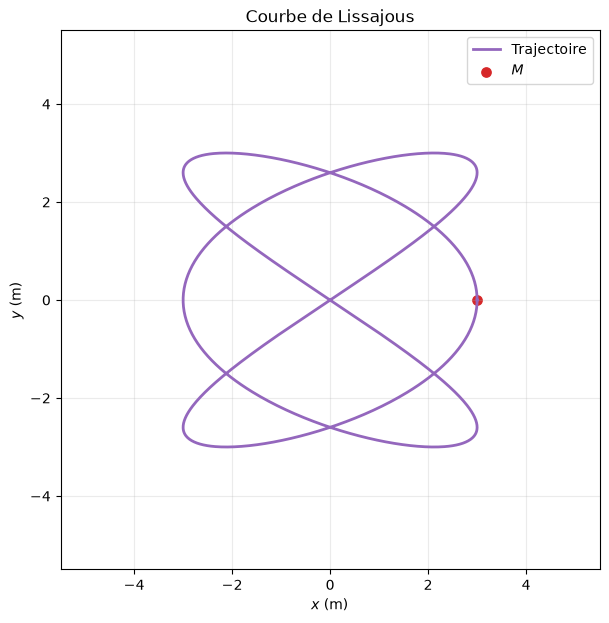

In [15]:
def tracer_lissajous(A=3.0, B=3.0, a=3.0, b=2.0,
                     phi=np.pi/2, t_current=2.0*np.pi):
    """Trace la courbe de Lissajous jusqu'à l'instant courant."""
    t = np.linspace(0.0, t_current, 1200)
    x, y = equations_horaires_lissajous(t, A=A, B=B, a=a, b=b, phi=phi)

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.plot(x, y, color='tab:purple', linewidth=2, label='Trajectoire')
    ax.scatter(x[-1], y[-1], color='tab:red', s=45, label='$M$')

    ax.set_xlim(-5.5, 5.5)
    ax.set_ylim(-5.5, 5.5)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel(r'$x$ (m)')
    ax.set_ylabel(r'$y$ (m)')
    ax.set_title('Courbe de Lissajous')
    ax.grid(alpha=0.25)
    ax.legend(loc='upper right')

    plt.show()
    plt.close(fig)

tracer_lissajous()

In [16]:
interact(
    tracer_lissajous,
    A=FloatSlider(value=3.0, min=1.0, max=5.0, step=0.1, description='A (m)'),
    B=FloatSlider(value=3.0, min=1.0, max=5.0, step=0.1, description='B (m)'),
    a=FloatSlider(value=3.0, min=1.0, max=6.0, step=0.1, description='a (rad/s)'),
    b=FloatSlider(value=2.0, min=1.0, max=6.0, step=0.1, description='b (rad/s)'),
    phi=FloatSlider(value=np.pi/2, min=0.0, max=2.0*np.pi, step=np.pi/12, description='φ (rad)'),
    t_current=FloatSlider(value=2.0*np.pi, min=0.1, max=4.0*np.pi, step=0.1, description='Temps (s)'),
);

interactive(children=(FloatSlider(value=3.0, description='A (m)', max=5.0, min=1.0), FloatSlider(value=3.0, de…

:::{important}
Pour afficher la version interactive, ouvrez le **Notebook enseignant** en
local ou ouvrez ce notebook dans Google Colab.
:::